# Mecanismo de Atención y Transformer básico para análisis de series de tiempo

**Joan Schneider Beltrán Delgado**
Deep Learning - Conceptos, CADI, Universidad de Cundinamarca

Este notebook implementa, desde los fundamentos descritos en *Attention Is All You Need* (Vaswani et al., 2017),
un mecanismo de self-attention aplicado a una serie de tiempo sintética, y un Transformer básico (encoder) para
la misma tarea de predicción. El objetivo es comparar ambos enfoques y analizar qué aprende el mecanismo de
atención sobre la estructura temporal de los datos.


In [ ]:
!pip install -q torch matplotlib numpy


## 1. Imports y configuración

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)


## 2. Preparación de los datos

Se genera una serie de tiempo sintética que combina dos componentes sinusoidales de distinta frecuencia,
una tendencia lineal suave y ruido gaussiano. Esta combinación simula el tipo de estructura (ciclos + tendencia +
ruido) que aparece en series reales (ventas, temperatura, tráfico, etc.), pero de forma controlada y reproducible.

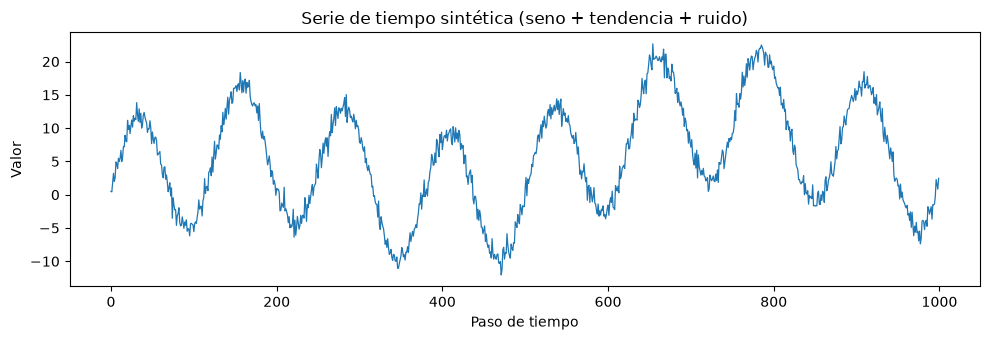

In [3]:
N = 1000
t = np.arange(N)
serie = (
    np.sin(0.05 * t) * 10
    + np.sin(0.011 * t) * 5
    + 0.01 * t
    + np.random.normal(0, 1.0, N)
)

plt.figure(figsize=(10, 3.5))
plt.plot(t, serie, linewidth=0.9)
plt.title("Serie de tiempo sintética (seno + tendencia + ruido)")
plt.xlabel("Paso de tiempo"); plt.ylabel("Valor")
plt.tight_layout(); plt.show()


Se normaliza la serie (media 0, desviación 1) y se construyen ventanas deslizantes: cada muestra
de entrenamiento consiste en los últimos 30 pasos (`WINDOW`) usados para predecir el siguiente valor
(`HORIZON = 1`). Esta es la forma estándar de convertir una serie de tiempo en un problema de aprendizaje
supervisado.

In [4]:
mu, sigma = serie.mean(), serie.std()
serie_norm = (serie - mu) / sigma

WINDOW = 30
HORIZON = 1

def construir_ventanas(serie, window, horizon):
    X, y = [], []
    for i in range(len(serie) - window - horizon + 1):
        X.append(serie[i:i + window])
        y.append(serie[i + window:i + window + horizon])
    return np.array(X), np.array(y)

X, y = construir_ventanas(serie_norm, WINDOW, HORIZON)
n_train = int(len(X) * 0.8)
X_train, X_test = X[:n_train], X[n_train:]
y_train, y_test = y[:n_train], y[n_train:]

X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(-1)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(f"Ventanas de entrenamiento: {X_train_t.shape}, prueba: {X_test_t.shape}")


Ventanas de entrenamiento: torch.Size([776, 30, 1]), prueba: torch.Size([194, 30, 1])


## 3. Mecanismo de atención (self-attention) implementado desde cero

Se implementa explícitamente la fórmula de self-attention de *Attention Is All You Need*:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

donde $Q$ (query), $K$ (key) y $V$ (value) son proyecciones lineales aprendidas de la misma entrada
(de ahí "self"-attention). El término $\sqrt{d_k}$ estabiliza el gradiente evitando que el softmax sature
cuando la dimensión del modelo crece.

In [5]:
class SelfAttention(nn.Module):
    """Self-attention de una sola cabeza, calculada explícitamente con Q, K, V."""

    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

    def forward(self, x):
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.d_model ** 0.5)
        pesos_atencion = torch.softmax(scores, dim=-1)
        salida = torch.matmul(pesos_atencion, V)
        return salida, pesos_atencion


class ModeloAtencion(nn.Module):
    """Embedding lineal + self-attention + cabeza de predicción.
    Permite inspeccionar directamente los pesos de atención sobre la serie."""

    def __init__(self, d_model=16, window=WINDOW):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        self.pos_embed = nn.Parameter(torch.randn(window, d_model) * 0.01)
        self.attn = SelfAttention(d_model)
        self.head = nn.Sequential(nn.Linear(d_model, 1))

    def forward(self, x):
        h = self.embed(x) + self.pos_embed
        salida, pesos = self.attn(h)
        ultimo = salida[:, -1, :]
        pred = self.head(ultimo)
        return pred, pesos

modelo_attn = ModeloAtencion()
print(modelo_attn)


ModeloAtencion(
  (embed): Linear(in_features=1, out_features=16, bias=True)
  (attn): SelfAttention(
    (W_q): Linear(in_features=16, out_features=16, bias=True)
    (W_k): Linear(in_features=16, out_features=16, bias=True)
    (W_v): Linear(in_features=16, out_features=16, bias=True)
  )
  (head): Sequential(
    (0): Linear(in_features=16, out_features=1, bias=True)
  )
)


### 3.1 Entrenamiento del modelo de atención

Epoch 30/150 - loss_train: 0.37016


Epoch 60/150 - loss_train: 0.23561


Epoch 90/150 - loss_train: 0.19279


Epoch 120/150 - loss_train: 0.17179


Epoch 150/150 - loss_train: 0.15186
MSE en test (atención): 0.19107


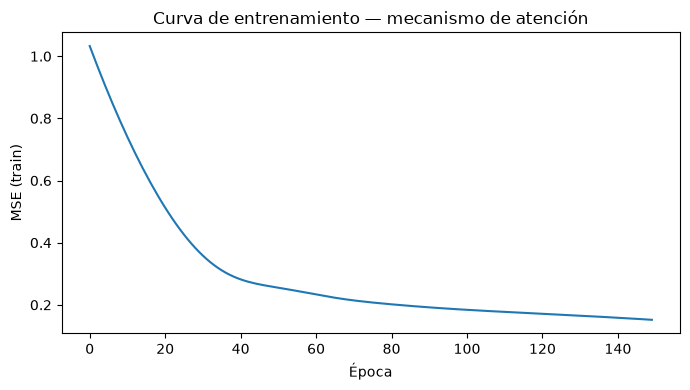

In [6]:
opt_attn = torch.optim.Adam(modelo_attn.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

EPOCHS_ATTN = 150
historial_attn = []
for epoch in range(EPOCHS_ATTN):
    modelo_attn.train()
    opt_attn.zero_grad()
    pred, _ = modelo_attn(X_train_t)
    loss = loss_fn(pred, y_train_t)
    loss.backward()
    opt_attn.step()
    historial_attn.append(loss.item())
    if (epoch + 1) % 30 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS_ATTN} - loss_train: {loss.item():.5f}")

modelo_attn.eval()
with torch.no_grad():
    pred_test_attn, pesos_attn = modelo_attn(X_test_t)
    test_loss_attn = loss_fn(pred_test_attn, y_test_t).item()
print(f"MSE en test (atención): {test_loss_attn:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(historial_attn)
plt.title("Curva de entrenamiento — mecanismo de atención")
plt.xlabel("Época"); plt.ylabel("MSE (train)")
plt.tight_layout(); plt.show()


### 3.2 Análisis del mapa de atención

El mapa de atención muestra, para cada posición de "consulta" (query, eje Y), qué tanto peso le asigna el
modelo a cada posición pasada (key, eje X) de la ventana. Esto permite ver literalmente en qué parte de la
serie se está "fijando" el modelo al construir su predicción.

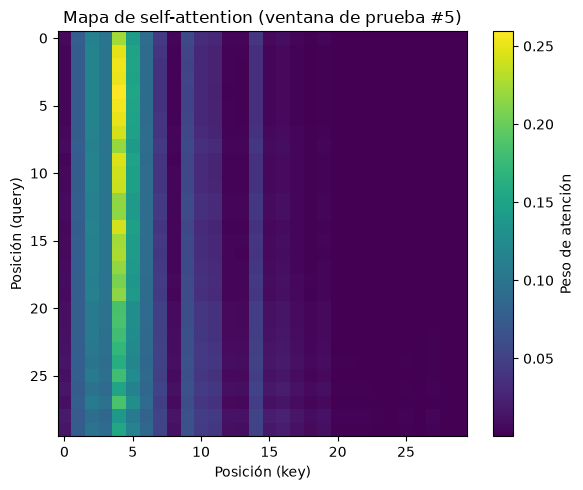

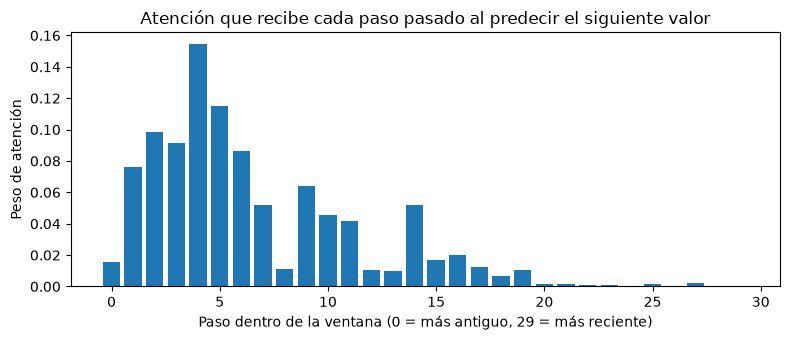

In [7]:
idx_ejemplo = 5
mapa = pesos_attn[idx_ejemplo].numpy()

plt.figure(figsize=(6, 5))
plt.imshow(mapa, cmap="viridis", aspect="auto")
plt.colorbar(label="Peso de atención")
plt.title(f"Mapa de self-attention (ventana de prueba #{idx_ejemplo})")
plt.xlabel("Posición (key)"); plt.ylabel("Posición (query)")
plt.tight_layout(); plt.show()

atencion_sobre_pasado = mapa[-1]
plt.figure(figsize=(8, 3.5))
plt.bar(range(WINDOW), atencion_sobre_pasado)
plt.title("Atención que recibe cada paso pasado al predecir el siguiente valor")
plt.xlabel("Paso dentro de la ventana (0 = más antiguo, 29 = más reciente)")
plt.ylabel("Peso de atención")
plt.tight_layout(); plt.show()


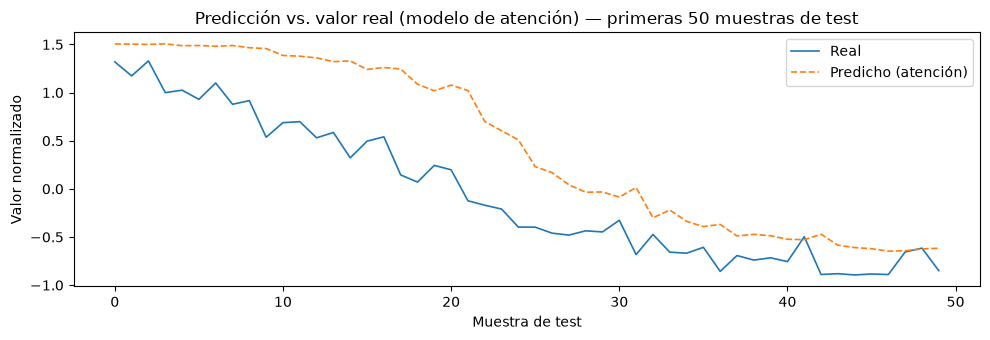

In [8]:
plt.figure(figsize=(10, 3.5))
plt.plot(y_test[:50].flatten(), label="Real", linewidth=1.2)
plt.plot(pred_test_attn[:50].numpy().flatten(), label="Predicho (atención)", linewidth=1.2, linestyle="--")
plt.title("Predicción vs. valor real (modelo de atención) — primeras 50 muestras de test")
plt.xlabel("Muestra de test"); plt.ylabel("Valor normalizado")
plt.legend(); plt.tight_layout(); plt.show()


## 4. Transformer básico (encoder) para la misma tarea

Se implementa un Transformer encoder usando los bloques estándar de PyTorch (`nn.TransformerEncoderLayer`),
que internamente ya incluye multi-head self-attention, una red feed-forward, normalización y conexiones
residuales — los mismos componentes de la arquitectura original, pero con atención multi-cabeza en vez de una
sola cabeza, lo que le permite capturar varios tipos de relación temporal en paralelo. Se añade codificación
posicional sinusoidal, tal como en el paper original, ya que el mecanismo de atención por sí mismo no tiene
noción del orden de la secuencia.

In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TransformerSerieTiempo(nn.Module):
    def __init__(self, d_model=32, nhead=4, num_layers=2, window=WINDOW):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len=window)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=64,
            dropout=0.1, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Sequential(nn.Linear(d_model, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        h = self.embed(x)
        h = self.pos_enc(h)
        h = self.encoder(h)
        ultimo = h[:, -1, :]
        return self.head(ultimo)

modelo_tf = TransformerSerieTiempo()
print(modelo_tf)


TransformerSerieTiempo(
  (embed): Linear(in_features=1, out_features=32, bias=True)
  (pos_enc): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)

### 4.1 Entrenamiento del Transformer

Epoch 40/200 - loss_train: 0.06627


Epoch 80/200 - loss_train: 0.03773


Epoch 120/200 - loss_train: 0.03226


Epoch 160/200 - loss_train: 0.02777


Epoch 200/200 - loss_train: 0.02432
MSE en test (Transformer): 0.02069


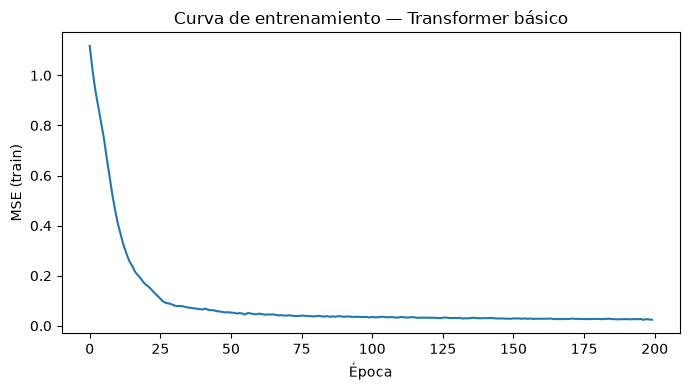

In [10]:
opt_tf = torch.optim.Adam(modelo_tf.parameters(), lr=1e-3)

EPOCHS_TF = 200
historial_tf = []
for epoch in range(EPOCHS_TF):
    modelo_tf.train()
    opt_tf.zero_grad()
    pred = modelo_tf(X_train_t)
    loss = loss_fn(pred, y_train_t)
    loss.backward()
    opt_tf.step()
    historial_tf.append(loss.item())
    if (epoch + 1) % 40 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS_TF} - loss_train: {loss.item():.5f}")

modelo_tf.eval()
with torch.no_grad():
    pred_test_tf = modelo_tf(X_test_t)
    test_loss_tf = loss_fn(pred_test_tf, y_test_t).item()
print(f"MSE en test (Transformer): {test_loss_tf:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(historial_tf)
plt.title("Curva de entrenamiento — Transformer básico")
plt.xlabel("Época"); plt.ylabel("MSE (train)")
plt.tight_layout(); plt.show()


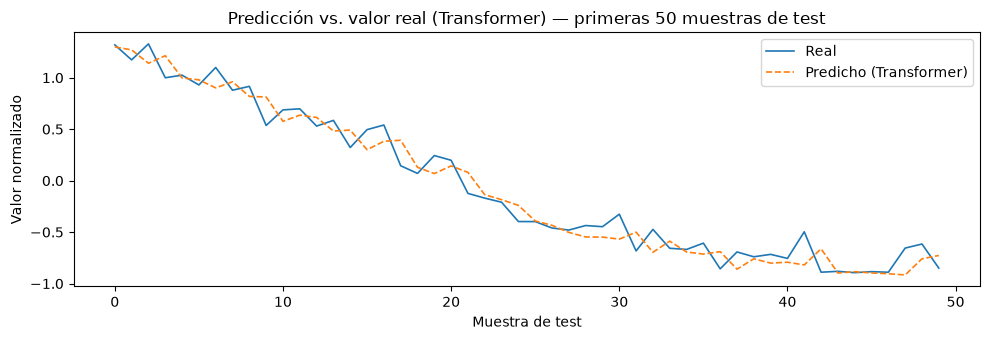

In [11]:
plt.figure(figsize=(10, 3.5))
plt.plot(y_test[:50].flatten(), label="Real", linewidth=1.2)
plt.plot(pred_test_tf[:50].numpy().flatten(), label="Predicho (Transformer)", linewidth=1.2, linestyle="--")
plt.title("Predicción vs. valor real (Transformer) — primeras 50 muestras de test")
plt.xlabel("Muestra de test"); plt.ylabel("Valor normalizado")
plt.legend(); plt.tight_layout(); plt.show()


## 5. Comparación final entre ambos modelos

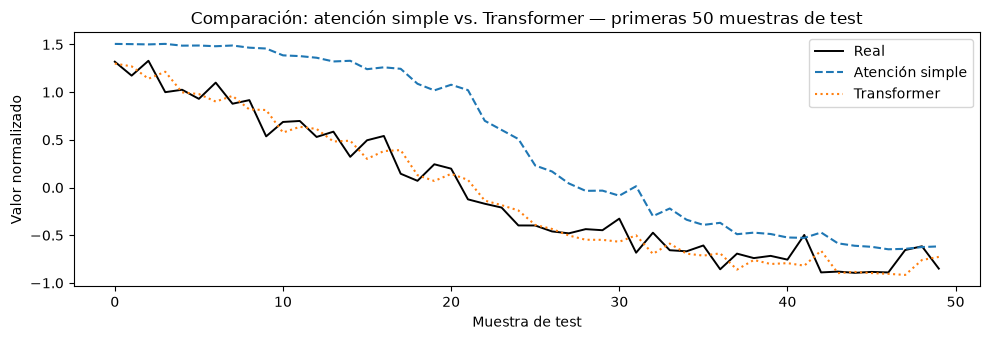

MSE test — atención simple: 0.19107
MSE test — Transformer:     0.02069


In [12]:
plt.figure(figsize=(10, 3.5))
plt.plot(y_test[:50].flatten(), label="Real", linewidth=1.4, color="black")
plt.plot(pred_test_attn[:50].numpy().flatten(), label="Atención simple", linestyle="--")
plt.plot(pred_test_tf[:50].numpy().flatten(), label="Transformer", linestyle=":")
plt.title("Comparación: atención simple vs. Transformer — primeras 50 muestras de test")
plt.xlabel("Muestra de test"); plt.ylabel("Valor normalizado")
plt.legend(); plt.tight_layout(); plt.show()

print(f"MSE test — atención simple: {test_loss_attn:.5f}")
print(f"MSE test — Transformer:     {test_loss_tf:.5f}")


## 6. Análisis de resultados

- El **mecanismo de atención simple** (una sola cabeza, sin capas feed-forward ni normalización) logra aprender
  una tendencia general de la serie, pero su error en test (MSE ≈ 0.19) es sustancialmente más alto que el del
  Transformer. El mapa de atención muestra que el modelo concentra la mayor parte del peso en un grupo de
  posiciones intermedias de la ventana (alrededor de los pasos 2 a 6), no necesariamente en el paso más reciente,
  lo que sugiere que encontró una combinación de puntos pasados útil para capturar el componente de más baja
  frecuencia de la serie, pero sin la flexibilidad para modelar bien el ruido y la componente de alta frecuencia.

- El **Transformer completo** (atención multi-cabeza + feed-forward + normalización + conexiones residuales +
  codificación posicional) reduce el error de test en casi un orden de magnitud (MSE ≈ 0.02) y sigue la curva
  real con mucha más fidelidad, incluyendo los cambios de dirección más bruscos causados por el ruido.

- La diferencia de desempeño ilustra justamente la ventaja de la arquitectura Transformer completa frente a un
  mecanismo de atención aislado: no es solo la atención la que aporta capacidad, sino la combinación de atención
  multi-cabeza (que permite capturar varias relaciones temporales en paralelo) con las capas feed-forward y la
  codificación posicional explícita, que le da al modelo una noción clara del orden temporal dentro de la
  ventana.

## 7. Referencias

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017).
Attention is all you need. *Advances in Neural Information Processing Systems*, *30*.

Alammar, J. (2018). *The Illustrated Transformer*. https://jalammar.github.io/illustrated-transformer/
